In [1]:
%load_ext autoreload
%autoreload 2

import glob

import cv2
import matplotlib.pyplot as plt

from tflite_inference import TFLiteInferer

2024-10-07 17:04:46.396870: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:485] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2024-10-07 17:04:46.413105: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:8454] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2024-10-07 17:04:46.418069: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1452] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2024-10-07 17:04:46.430500: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2024-10-07 17:04:47.316119: W tensorflow/compiler/tf2

TensorFlow version:  2.17.0


In [2]:
tst_img_paths = sorted(glob.glob("/home/klymy/data/people_detection/filtered_v3_margin_15/images/algotest/*.jpg"))
len(tst_img_paths)

9572

INFO: Created TensorFlow Lite XNNPACK delegate for CPU.


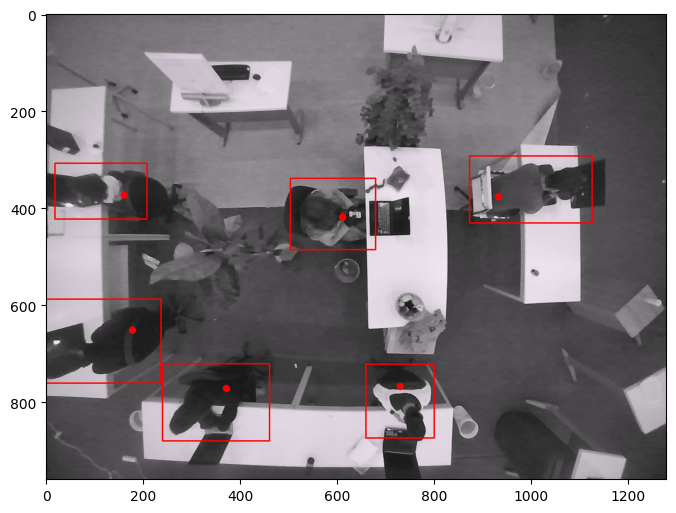

In [3]:
img = cv2.cvtColor(cv2.imread(tst_img_paths[1001]), cv2.COLOR_BGR2RGB)

ORIGINAL_H, ORIGIAL_W, _ = img.shape
W = H = 320
RATIO = W / ORIGIAL_W

inferer = TFLiteInferer(
    yolo_pth="results/filtered_v3_margin_15/weights/best_saved_model/best_full_integer_quant.tflite",
    head_pth="results/filtered_v3_margin_15/weights/head_saved_model/head_float32.tflite"
)

detections = inferer.infer(img)

for box in detections:
    cv2.rectangle(img, (box[:2] / RATIO).astype(int), ((box[:2].astype(int) + box[2:4]) / RATIO).astype(int) , (255, 0, 0), 2)

for p in detections:
    cv2.circle(img, (p[-2:] // RATIO).astype(int), 4, (255, 0, 0), 5)

plt.figure(figsize=(8, 8))
plt.imshow(img)